# Weighted PageRank in Tennis — 2025 ATP season
**Chakib Madcur · Progress update**

What we agreed to do next:
1. Develop the first **directed graph** from the dataset
2. Build a **system that assigns weights** to edges and nodes from the dataset (matches won)
3. Write a **weighted PageRank program** and apply it to the graph

## Step 1 · Load the data
All ATP tour-level matches from 2025 (Jeff Sackmann's dataset). I remove Davis Cup, the Next Gen Finals exhibition, and walkovers.

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/atp/"   # copy of Sackmann's data

matches = pd.read_csv(DATA + "atp_matches_2025.csv")
matches = matches[(matches.tourney_level != "D")
                  & (matches.tourney_name != "Next Gen Finals")
                  & (~matches.score.astype(str).str.contains("W/O", na=False))]

names = dict(zip(matches.winner_id, matches.winner_name)) | dict(zip(matches.loser_id, matches.loser_name))
print(f"{len(matches):,} matches, {len(names)} players")

2,655 matches, 292 players


## Step 2 · Build the directed graph
- Each **player** is a node.
- Each **match** is an arrow from the **loser to the winner**.
- **Edge weight = matches won.** If a player beat the same opponent twice, the arrow has weight 2 and counts more than a single win.

In [2]:
G = nx.DiGraph()
for loser, winner in zip(matches.loser_id, matches.winner_id):
    if G.has_edge(loser, winner):
        G[loser][winner]["weight"] += 1      # another win over the same player
    else:
        G.add_edge(loser, winner, weight=1)

print(f"Nodes: {G.number_of_nodes()}   Edges: {G.number_of_edges()}")
print("Edges with weight 2 or more:", sum(1 for _, _, w in G.edges(data="weight") if w >= 2))

# Example: Alcaraz vs Sinner in 2025
alcaraz = next(p for p in names if names[p] == "Carlos Alcaraz")
sinner  = next(p for p in names if names[p] == "Jannik Sinner")
print("Sinner -> Alcaraz weight:", G[sinner][alcaraz]["weight"], " (Alcaraz won 4 times)")
print("Alcaraz -> Sinner weight:", G[alcaraz][sinner]["weight"], " (Sinner won 2 times)")

Nodes: 292   Edges: 2395
Edges with weight 2 or more: 218
Sinner -> Alcaraz weight: 4  (Alcaraz won 4 times)
Alcaraz -> Sinner weight: 2  (Sinner won 2 times)


**The graph for the ATP top 10 only** (thicker arrow = more wins):

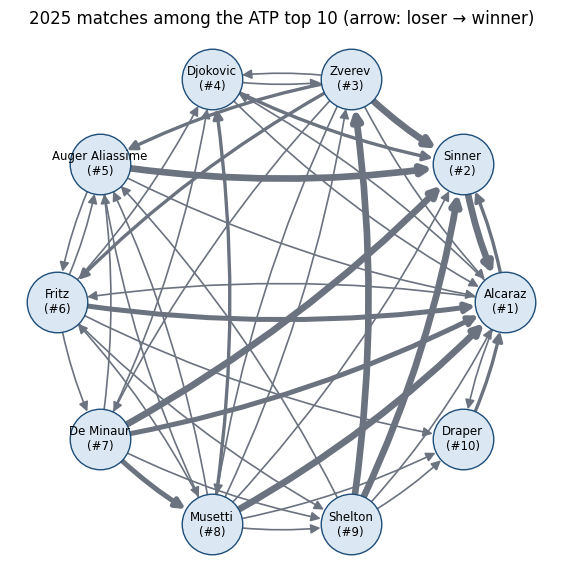

In [3]:
rankings = pd.read_csv(DATA + "atp_rankings_20s.csv")
year_end = rankings[rankings.ranking_date == 20251229]            # ATP ranking at the end of 2025
atp_rank = dict(zip(year_end.player, year_end["rank"]))

top10 = [p for p in G if atp_rank.get(p, 999) <= 10]
H = G.subgraph(top10)
pos = nx.circular_layout(sorted(H, key=lambda p: atp_rank[p]))
labels = {p: " ".join(names[p].split()[1:]) + f"\n(#{atp_rank[p]})" for p in H}

plt.figure(figsize=(7, 7))
nx.draw_networkx_nodes(H, pos, node_size=1900, node_color="#dbe7f3", edgecolors="#1f4e79")
nx.draw_networkx_labels(H, pos, labels, font_size=8.5)
nx.draw_networkx_edges(H, pos, width=[1.2 * H[u][v]["weight"] for u, v in H.edges()],
                       edge_color="#6b7280", arrowsize=14, node_size=1900, connectionstyle="arc3,rad=0.08")
plt.title("2025 matches among the ATP top 10 (arrow: loser → winner)")
plt.axis("off"); plt.show()

## Step 3 · Weights for the nodes
The edges already carry **matches won**. For the nodes, each player's weight is also their **number of matches won** (plus 1, so players with no wins are not left at zero).

In [4]:
wins = matches.winner_id.value_counts()
node_weight = {p: wins.get(p, 0) + 1 for p in G}

pd.DataFrame({"Player": [names[p] for p in wins.index[:5]], "Matches won": wins.values[:5]})

,Player,Matches won
0,Carlos Alcaraz,71
1,Jannik Sinner,58
2,Alexander Zverev,55
3,Alex De Minaur,54
4,Taylor Fritz,52


## Step 4 · The weighted PageRank program
Each player starts with the same score. In every round, each player passes their score to the players who beat them, **in proportion to the edge weights**. A small part of the score (15%) is shared out according to the **node weights**. After enough rounds the scores stop changing: that is the ranking.

In [5]:
def weighted_pagerank(G, node_weight, d=0.85, rounds=100):
    total = sum(node_weight.values())
    share = {p: node_weight[p] / total for p in G}                  # node weights
    out = {p: G.out_degree(p, weight="weight") for p in G}          # total weight of each player's losses
    score = {p: 1 / len(G) for p in G}                              # everyone starts equal

    for _ in range(rounds):
        new = {p: (1 - d) * share[p] for p in G}
        unbeaten = sum(score[p] for p in G if out[p] == 0)          # players with no losses pass to everyone
        for p in G:
            new[p] += d * unbeaten * share[p]
        for loser, winner, w in G.edges(data="weight"):
            new[winner] += d * score[loser] * w / out[loser]        # loser passes score to winner, by weight
        score = new
    return score

pr = weighted_pagerank(G, node_weight)

# check: same answer as the NetworkX library
check = nx.pagerank(G, alpha=0.85, personalization=node_weight, weight="weight", tol=1e-12)
print("Largest difference vs NetworkX:", f"{max(abs(pr[p] - check[p]) for p in G):.0e}", "-> same result")

Largest difference vs NetworkX: 1e-11 -> same result


## Result · Top 10 by weighted PageRank

In [6]:
players = list(G)
table = pd.DataFrame({"Player": [names[p] for p in players],
                      "Weighted PageRank": pd.Series(pr)[players].rank(ascending=False).astype(int).values,
                      "ATP rank": [atp_rank.get(p) for p in players],
                      "Matches won": [wins.get(p, 0) for p in players]}, index=players)
table["ATP rank"] = table["ATP rank"].astype("Int64")
table = table.sort_values("Weighted PageRank")
table.head(10).set_index("Weighted PageRank")

,Player,ATP rank,Matches won
Weighted PageRank,,,
1,Carlos Alcaraz,1,71
2,Jannik Sinner,2,58
3,Taylor Fritz,6,52
4,Alexander Zverev,3,55
5,Novak Djokovic,4,39
6,Alexander Bublik,11,37
7,Felix Auger Aliassime,5,50
8,Alex De Minaur,7,54
9,Jiri Lehecka,18,38


## Extra 1 · Comparison with the ATP ranking

In [7]:
pr_top10 = set(table.index[:10])
atp_top10 = {p for p in table.index if atp_rank.get(p, 999) <= 10}
top100 = table[table["ATP rank"] <= 100]

print(f"Players in both top 10s: {len(pr_top10 & atp_top10)} of 10")
print(f"Rank correlation with ATP (top 100): {top100['ATP rank'].corr(top100['Weighted PageRank'], method='spearman'):.2f}   (1.00 = identical order)")

Players in both top 10s: 8 of 10


Rank correlation with ATP (top 100): 0.92   (1.00 = identical order)


## Extra 2 · Making big tournaments count more
Same graph and program, but each win is now weighted by the tournament: **Grand Slam = 2**, **Masters 1000 and ATP Finals = 1.5**, **other tournaments = 1**.

In [8]:
LEVEL = {"G": 2.0, "M": 1.5, "F": 1.5, "A": 1.0}

G_big = nx.DiGraph()
for loser, winner, level in zip(matches.loser_id, matches.winner_id, matches.tourney_level):
    w = LEVEL[level]
    if G_big.has_edge(loser, winner):
        G_big[loser][winner]["weight"] += w
    else:
        G_big.add_edge(loser, winner, weight=w)

pr_big = weighted_pagerank(G_big, node_weight)
table["Big tournaments"] = pd.Series(pr_big)[table.index].rank(ascending=False).astype(int).values
table["Change"] = table["Weighted PageRank"] - table["Big tournaments"]      # + = moved up

table.sort_values("Big tournaments").head(10)[["Player", "Weighted PageRank", "Big tournaments", "Change", "ATP rank"]].set_index("Big tournaments")

,Player,Weighted PageRank,Change,ATP rank
Big tournaments,,,,
1,Carlos Alcaraz,1,0,1
2,Jannik Sinner,2,0,2
3,Novak Djokovic,5,2,4
4,Taylor Fritz,3,-1,6
5,Alexander Zverev,4,-1,3
6,Alexander Bublik,6,0,11
7,Felix Auger Aliassime,7,0,5
8,Jack Draper,10,2,10
9,Alex De Minaur,8,-1,7


## Findings
- The directed, weighted graph of 2025 has **292 players and 2,395 edges**; 218 of those edges have weight 2 or more (the same player won more than once).
- Weighted PageRank finds the same top 2 as the ATP (Alcaraz, Sinner) and agrees on **8 of the top 10**.
- Making big tournaments count more changes the top 10 slightly: Djokovic, Draper and Musetti move up (strong Grand Slam and Masters results), while Fritz, Zverev and de Minaur move down one place each.

**Questions for next time**
1. Which other factors should the weight system include (round, surface, score, opponent's ranking)?
2. Should I extend this to more seasons next?